In [166]:
from pydoc import describe

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import shapiro
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, \
    f1_score
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from statsmodels.stats.descriptivestats import Describe



In [24]:
data = pd.read_csv('./data/bank.csv', na_values=['-',' ',''],encoding='latin1')



In [25]:
data['Stayed'] = np.where(data['Exited']==0 , 'Yes','No')
data['Stayed'] = data['Stayed'].map({'Yes': 1, 'No': 0})

data.drop(columns=['Exited'], inplace=True)


In [26]:
print(data.isna().sum())

Surname               1
CreditScore           0
Geography             2
Gender                0
Age                   3
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64


In [27]:
data['Age'].fillna(data['Age'].median())

0       37.0
1       41.0
2       42.0
3       39.0
4       43.0
        ... 
4893    32.0
4894    31.0
4895    41.0
4896    40.0
4897    40.0
Name: Age, Length: 4898, dtype: float64

In [28]:
data_sub =data.loc[data['Age']<=87].copy()
print(data_sub.info())
print(data_sub.isna().sum())

<class 'pandas.DataFrame'>
Index: 4894 entries, 1 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4893 non-null   str    
 1   CreditScore         4894 non-null   int64  
 2   Geography           4892 non-null   str    
 3   Gender              4894 non-null   str    
 4   Age                 4894 non-null   float64
 5   Tenure              4894 non-null   int64  
 6   Balance             4894 non-null   float64
 7   NumOfProducts       4894 non-null   int64  
 8   HasCrCard           4894 non-null   int64  
 9   IsActiveMember      4894 non-null   int64  
 10  EstimatedSalary     4894 non-null   float64
 11  Satisfaction.Score  4894 non-null   int64  
 12  Card.Type           4894 non-null   str    
 13  Point.Earned        4894 non-null   int64  
 14  Stayed              4894 non-null   int64  
dtypes: float64(3), int64(8), str(4)
memory usage: 611.8 KB
None
Surname    

In [29]:
print(data_sub.isna().sum())

Surname               1
CreditScore           0
Geography             2
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64


In [ ]:
#   data_sub['Geography']=data_sub['Geography'].fillna(data_sub['Geography'].mode()[0])

In [30]:
data_sub.drop(columns=['Surname'], inplace=True)

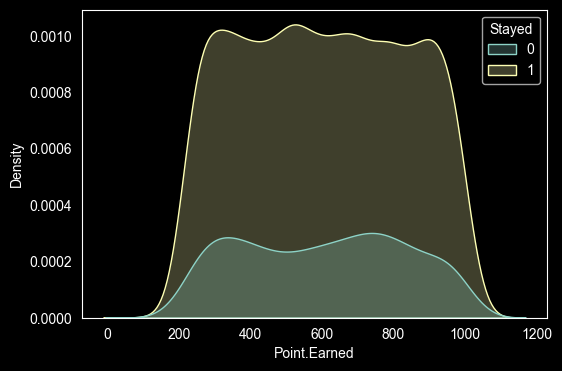

In [62]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='Point.Earned',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [63]:
data_sub.drop(columns=['Point.Earned'], inplace=True)

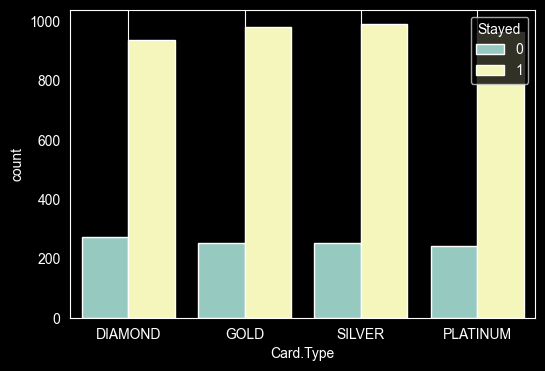

In [60]:
plt.figure(figsize=(6,4))
sns.countplot(data=data_sub,x='Card.Type',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [71]:
data_sub.drop(columns=['Card.Type'], inplace=True)

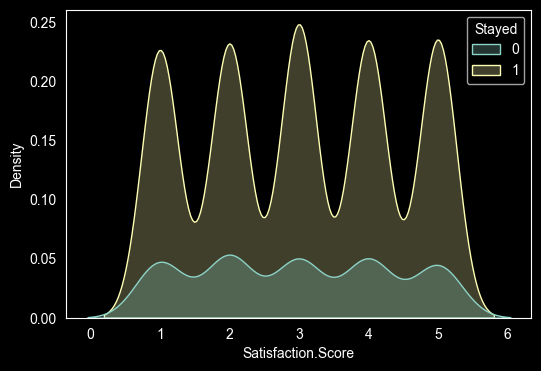

In [57]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='Satisfaction.Score',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [64]:
data_sub.drop(columns=['Satisfaction.Score'], inplace=True)

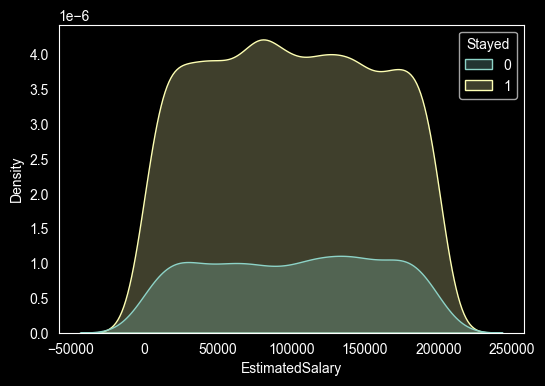

In [56]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='EstimatedSalary',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [65]:
data_sub.drop(columns=['EstimatedSalary'], inplace=True)

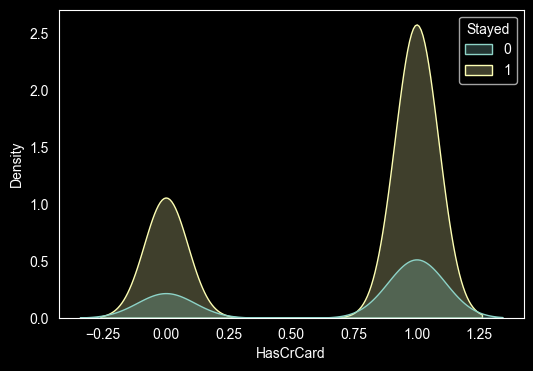

In [54]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='HasCrCard',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [66]:
data_sub.drop(columns=['HasCrCard'], inplace=True)

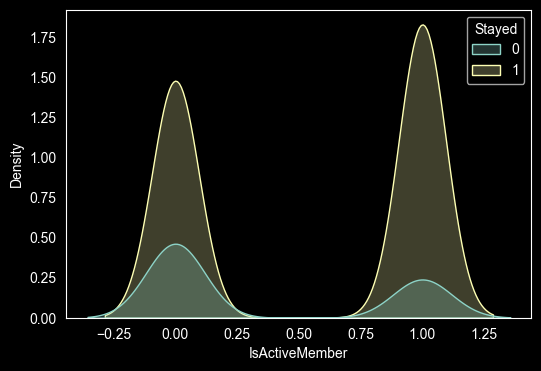

In [55]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='IsActiveMember',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [67]:
data_sub.drop(columns=['IsActiveMember'], inplace=True)

In [38]:
print(data_sub['Geography'].mode())

data_sub['Geography']=data_sub['Geography'].fillna(data_sub['Geography'].mode()[0])
print(data_sub['Geography'].isna().sum())
print(data_sub.isna().sum())

0    France
Name: Geography, dtype: str
0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0
Stayed                0
dtype: int64


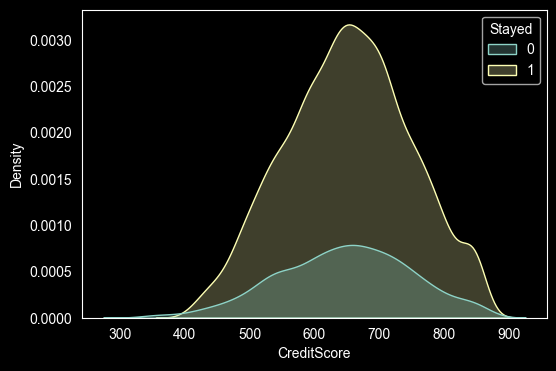

In [45]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='CreditScore',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [68]:
data_sub.drop(columns=['CreditScore'], inplace=True)

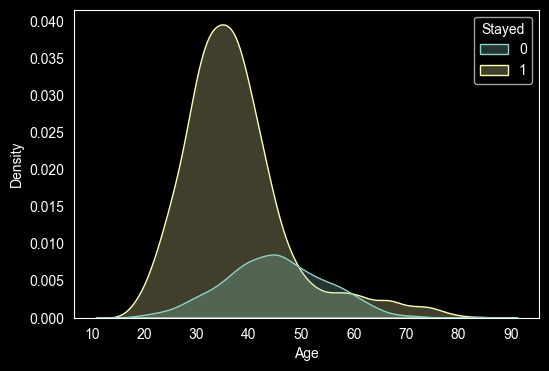

In [46]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='Age',hue='Stayed',fill=True)
plt.grid()
plt.show()

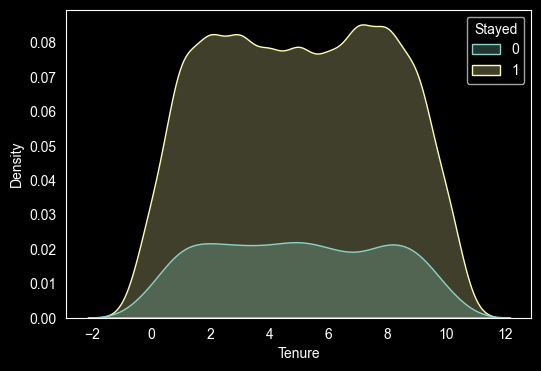

In [51]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='Tenure',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [69]:
data_sub.drop(columns=['Tenure'], inplace=True)

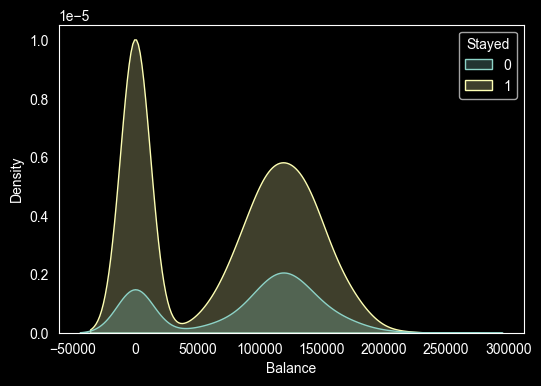

In [52]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='Balance',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [70]:
data_sub.drop(columns=['Balance'], inplace=True)

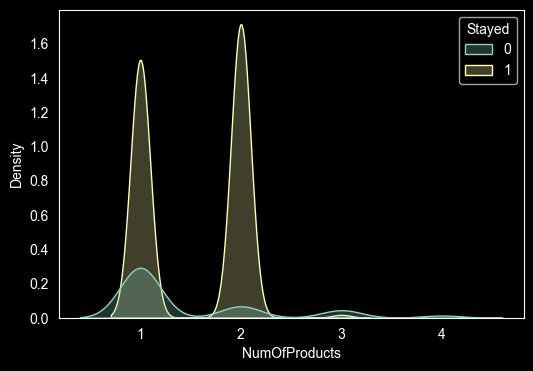

In [53]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=data_sub,x='NumOfProducts',hue='Stayed',fill=True)
plt.grid()
plt.show()

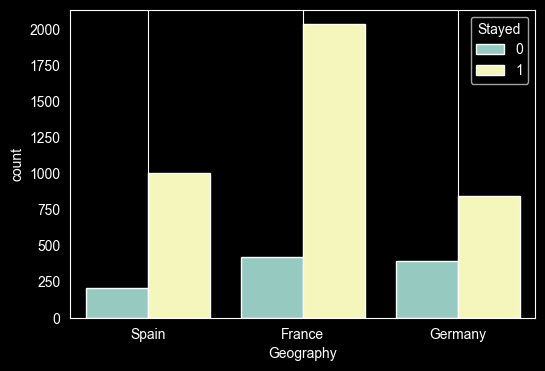

In [50]:
plt.figure(figsize=(6,4))
sns.countplot(data=data_sub,x='Geography',hue='Stayed',fill=True)
plt.grid()
plt.show()

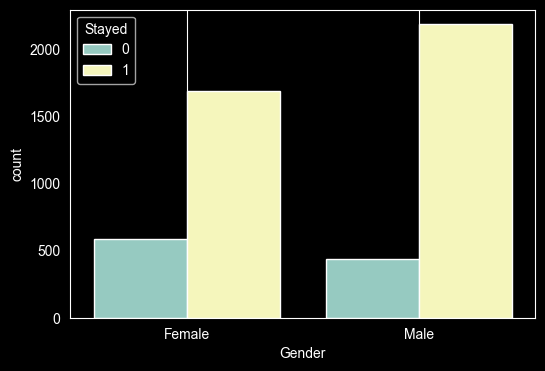

In [48]:
plt.figure(figsize=(6,4))
sns.countplot(data=data_sub,x='Gender',hue='Stayed',fill=True)
plt.grid()
plt.show()

In [76]:
print(data_sub.head())
print(data_sub.describe())

  Geography  Gender   Age  NumOfProducts  Stayed
1     Spain  Female  41.0              1       1
2    France  Female  42.0              3       0
3    France  Female  39.0              2       1
4     Spain  Female  43.0              1       1
5     Spain    Male  44.0              2       0
               Age  NumOfProducts       Stayed
count  4894.000000    4894.000000  4894.000000
mean     38.968124       1.523907     0.791377
std      10.591644       0.582934     0.406366
min      18.000000       1.000000     0.000000
25%      32.000000       1.000000     1.000000
50%      37.000000       1.000000     1.000000
75%      44.000000       2.000000     1.000000
max      85.000000       4.000000     1.000000


In [79]:
print(data_sub.info())

<class 'pandas.DataFrame'>
Index: 4894 entries, 1 to 4897
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Geography      4894 non-null   str    
 1   Gender         4894 non-null   str    
 2   Age            4894 non-null   float64
 3   NumOfProducts  4894 non-null   int64  
 4   Stayed         4894 non-null   int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 229.4 KB
None


In [82]:
data_sub.Geography.value_counts()



Geography
France     2454
Germany    1231
Spain      1209
Name: count, dtype: int64

In [83]:
data_sub.Gender.value_counts()

Gender
Male      2622
Female    2272
Name: count, dtype: int64

**OHE algoritam za promenu str/obj u numeric**

In [85]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
p = ['Geography','Gender']

enc = ohe.fit_transform(data_sub[p])
enc_col =ohe.get_feature_names_out(p)

data_ohe = pd.DataFrame(enc, columns=enc_col,index=data_sub.index)
data_sub = data_sub.drop(columns=p).join(data_ohe)

In [ ]:
ohe = OneHotEncoder(sparse_output=False,drop='first')
enc_array = ohe.fit_transform(data_sub[p])
col=ohe.get_feature_names_out(p)
da_s = pd.DataFrame(enc_array, columns=col,index=data_sub.index)
data_sub = data_sub.drop(columns=p).join(da_s)

In [87]:
# OHE ALGORITAM PONOVO vezba
ohe = OneHotEncoder(sparse_output=False,drop='first')
v =['Geography','Gender']

enc_array = ohe.fit_transform(data_sub[v])
enc_col = ohe.get_feature_names_out(v)

data_ohe = pd.DataFrame(enc_array, columns= enc_col, index=data_sub.index)
data_sub = data_sub.drop(colomns=v).join(data_ohe)

In [86]:
data_sub.head(10)

,Age,NumOfProducts,Stayed,Geography_Germany,Geography_Spain,Gender_Male
1,41.0,1,1,0.0,1.0,0.0
2,42.0,3,0,0.0,0.0,0.0
3,39.0,2,1,0.0,0.0,0.0
4,43.0,1,1,0.0,1.0,0.0
5,44.0,2,0,0.0,1.0,1.0
6,50.0,2,1,0.0,0.0,1.0
7,29.0,4,0,1.0,0.0,0.0
8,44.0,2,1,0.0,0.0,1.0
9,27.0,1,1,0.0,0.0,1.0
10,31.0,2,1,0.0,0.0,1.0


In [89]:
X = data_sub.drop(columns = 'Stayed')
y = data_sub['Stayed']

X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.2,random_state=42,stratify=y)


In [91]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Stayed
1    0.791411
0    0.208589
Name: proportion, dtype: float64
Stayed
1    0.791369
0    0.208631
Name: proportion, dtype: float64


In [151]:
##Kros validacija za najbolji parametar ccp
tree = DecisionTreeClassifier()
cv = StratifiedKFold(n_splits=10,shuffle=True,random_state=42)

param_grid={'ccp_alpha':np.arange(0.0,0.05,0.0025)}
grid = GridSearchCV(estimator=tree,
                    param_grid=param_grid,
                    cv=cv,
                    scoring='accuracy')
grid.fit(X_train,y_train)

best_ccp = grid.best_params_['ccp_alpha']
print(best_ccp)

0.005


In [ ]:
tre = DecisionTreeClassifier()

cv = StratifiedKFold(n_splits=10,shuffle=True,random_state=42)

param = {'ccp_alpha':np.arange(0.0,0.05,0.0025)}
grid = GridSearchCV(estimator=tree,
                    param_grid=param,
                    cv=cv,
                    scoring='accuracy')
grid.fit(X_train,y_train)
best_ccp = grid.best_params_['ccp_alpha']

In [ ]:
X = data_sub.drop(columns = 'Stayed')
y=data_sub['Stayed']

X_train,X_test,y_train,y_test = train_test_split(X,y,train_size=0.2,random_state=42,stratify=y)


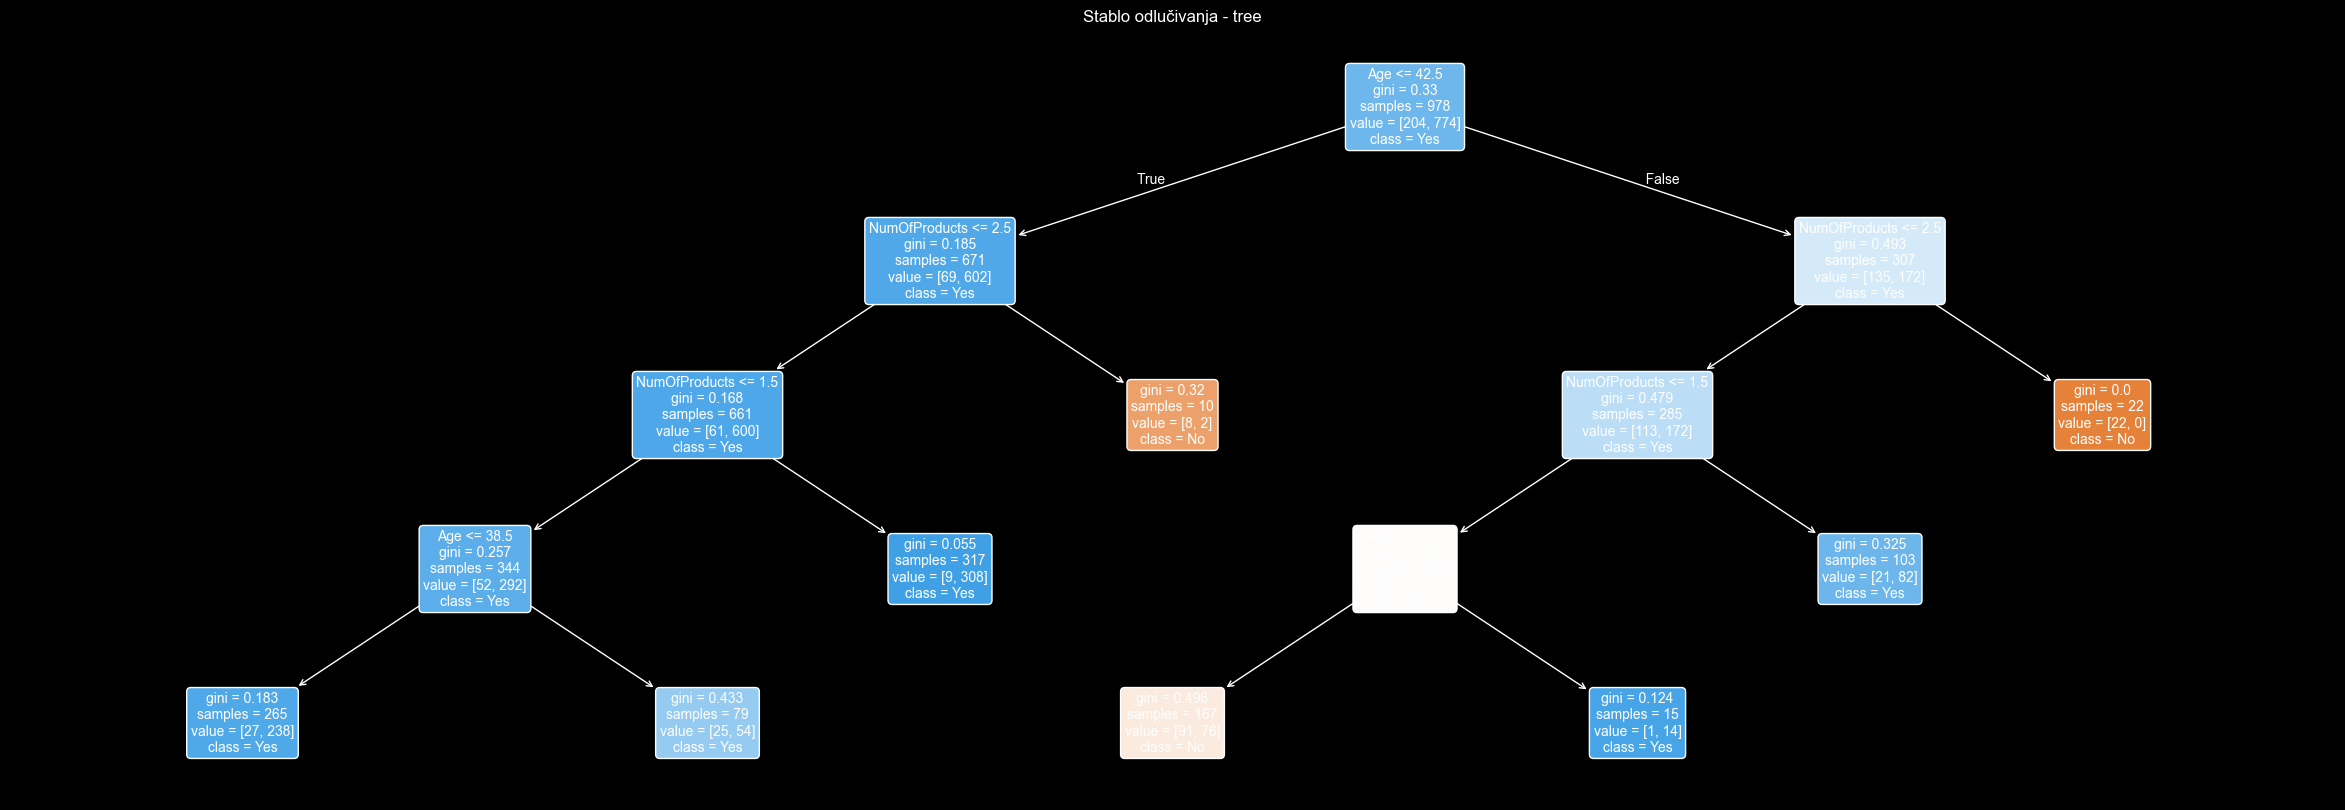

In [152]:
tree = DecisionTreeClassifier(ccp_alpha=best_ccp,random_state=42)
tree.fit(X_train, y_train)

# Vizualizacija stabla odlučivanja
plt.figure(figsize=[30,10])
plot_tree(tree,
          feature_names=X_train.columns,
          class_names=['No','Yes'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Stablo odlučivanja - tree")
plt.show()

In [153]:
y_pred = tree.predict(X_test)

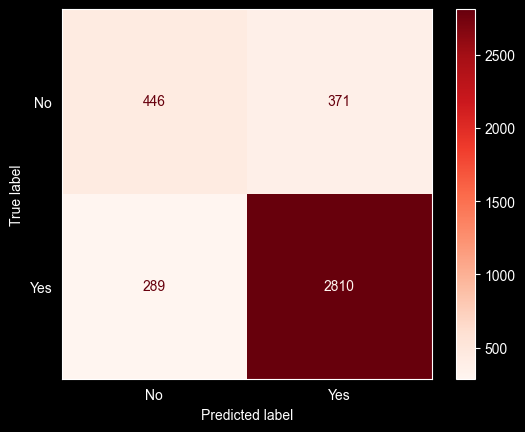

In [171]:
cm = confusion_matrix(y_test,y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['No','Yes'])
disp.plot(cmap=plt.cm.Reds)
plt.grid()
plt.show()

In [ ]:
cm =confusion_matrix(y_test,y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=['Nije','Yeste'])

disp.plot(cmap=plt.cm.Blues)
plt.grid()
plt.show()

In [167]:
def matrix_met(y_true, y_pred):
    accuracy = accuracy_score(y_true,y_pred)
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true,y_pred)
    f1 = f1_score(y_true,y_pred)
    return { 'accuracy': accuracy,
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)}
mm=matrix_met(y_test,y_pred)
print(f"{mm}")

{'accuracy': 0.8314606741573034, 'precision': 0.8833700094309965, 'recall': 0.9067441110035496, 'f1': 0.8949044585987261}
